In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# Calidad de vida y pobreza multidimensional

La Encuesta Nacional de Calidad de Vida (ECV) del DANE pregunta cada año a unos 90.000 hogares por su vivienda, sus
servicios, su salud, su educación y su trabajo. Con ella el DANE calcula el Índice de Pobreza Multidimensional (IPM). Aquí se
ven tres cosas: cuánto bajó la pobreza multidimensional de 2018 a 2025, en qué departamentos sigue alta y qué privaciones
explican la caída.

Hace falta la ECV descargada: `dd.ecv.download(range(2018, 2026))` baja los once capítulos de cada año.

In [2]:
import dane_data as dd

ipm = dd.ecv.serie_ipm(range(2018, 2026))
ipm[["anio", "incidencia", "intensidad", "ipm"]].round(3)

,anio,incidencia,intensidad,ipm
0,2018,19.121,41.724,0.080
1,2019,17.452,41.373,0.072
2,2020,14.828,40.817,0.061
3,2021,15.966,40.809,0.065
4,2022,12.923,40.265,0.052
5,2023,12.134,40.083,0.049
6,2024,11.530,40.203,0.046
7,2025,9.913,40.380,0.040


## La pobreza multidimensional bajó a la mitad

En 2018, el 19,1 % de las personas vivía en un hogar con privaciones en al menos un tercio de las 15 variables del IPM; en
2025, el 9,9 %. La intensidad, el puntaje promedio de los pobres, casi no cambió: hay menos pobres, pero los que quedan
tienen tantas privaciones como antes. 2020 sale más bajo que lo publicado (18,1 %), porque el DANE armó ese año la
inasistencia escolar con el SIMAT, que no está en los microdatos.

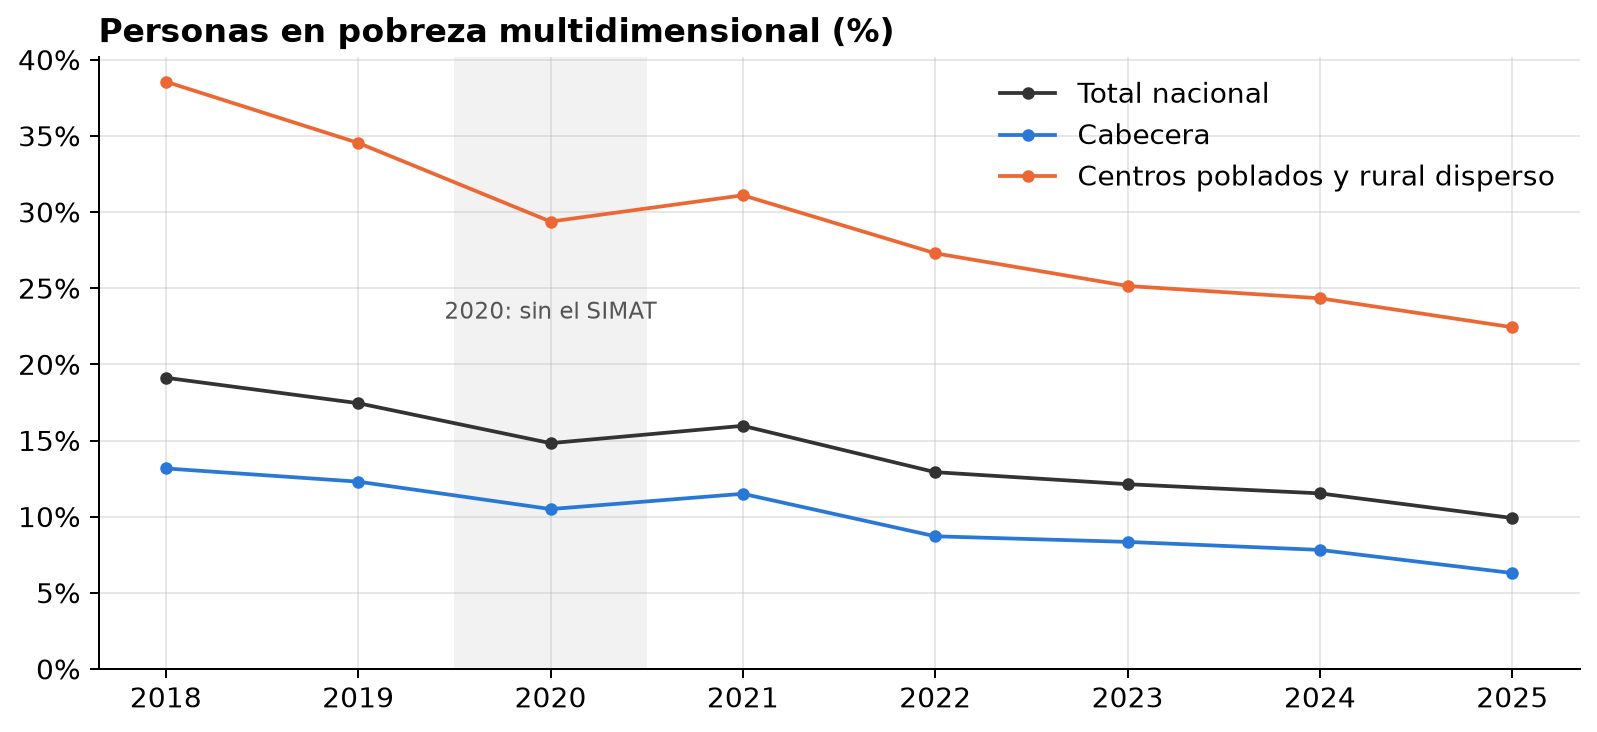

In [3]:
area = dd.ecv.serie_ipm(range(2018, 2026), por="area")
fig, ax = plt.subplots()
ax.plot(ipm["anio"], ipm["incidencia"], marker="o", markersize=4, color="#333333", label="Total nacional")
for nombre, d in area.groupby("area", observed=True):
    ax.plot(d["anio"], d["incidencia"], marker="o", markersize=4, label=nombre)
ax.axvspan(2019.5, 2020.5, color="#999999", alpha=0.12, lw=0)
ax.annotate("2020: sin el SIMAT", (2020, 23), ha="center", fontsize=9, color="#555555")
ax.set_title("Personas en pobreza multidimensional (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(bottom=0)
ax.legend()
fig.tight_layout()

## Los departamentos

Las cifras departamentales usan toda la muestra, como en los anexos del DANE (las nacionales y por área dejan fuera la parte
rural de los ocho departamentos de la Orinoquía-Amazonía). En 2025 la incidencia va de 2,2 % en Bogotá a 55,2 % en Vichada:
Guainía, Vaupés y La Guajira también pasan del 40 %.

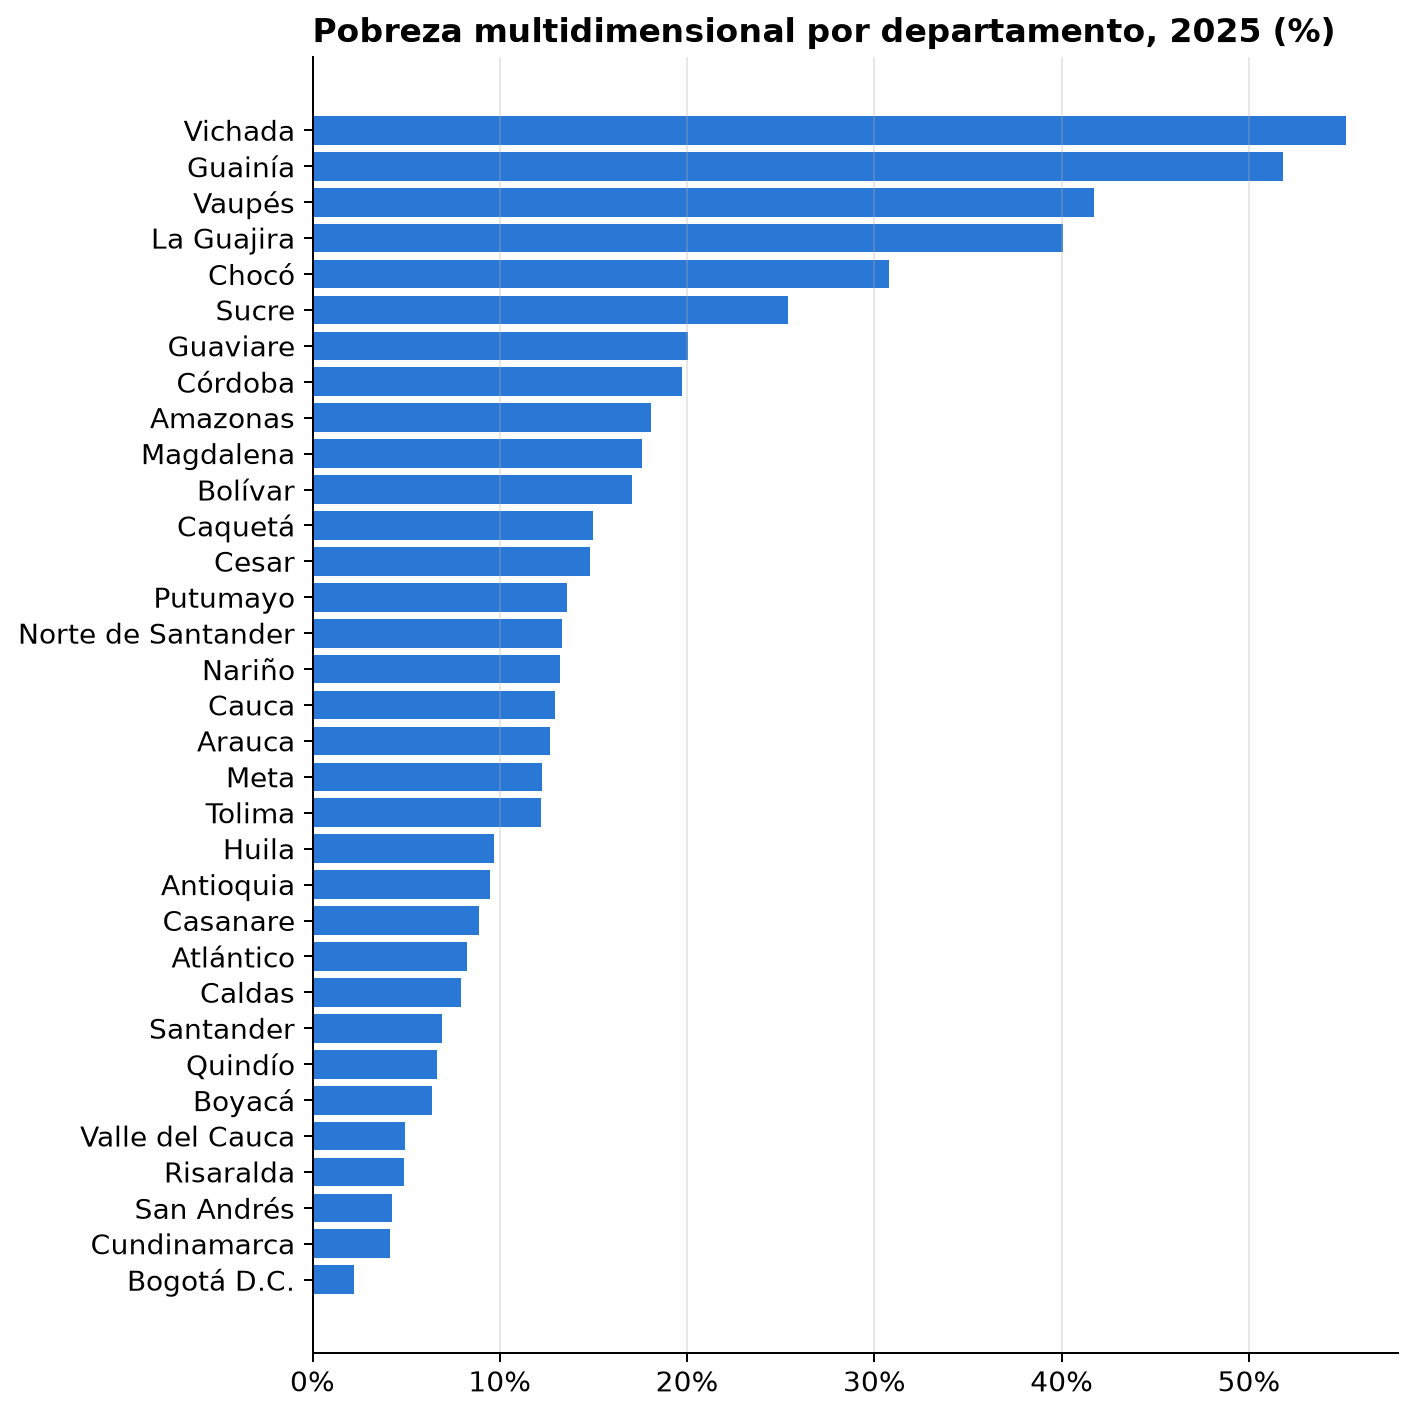

In [4]:
dptos = dd.ecv.serie_ipm(2025, por="departamento").sort_values("incidencia")
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(dptos["departamento"].astype(str), dptos["incidencia"], color="#2a78d6")
ax.set_title("Pobreza multidimensional por departamento, 2025 (%)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
fig.tight_layout()

## Qué privaciones bajaron

Las privaciones se miden como % de hogares. Las que más bajaron de 2018 a 2025 son el bajo logro educativo y el rezago
escolar (7,7 puntos cada una) y la falta de aseguramiento en salud (6,3). El trabajo informal sigue siendo la más común: 70 %
de los hogares tiene al menos un miembro en la fuerza de trabajo sin cotizar a pensión. El desempleo de larga duración es la
única que sube.

In [5]:
nombres = {"logro_educativo": "Bajo logro educativo", "rezago_escolar": "Rezago escolar",
           "aseguramiento_salud": "Sin aseguramiento en salud", "analfabetismo": "Analfabetismo",
           "barreras_acceso_salud": "Barreras de acceso a salud", "acueducto": "Sin agua mejorada",
           "atencion_integral": "Barreras primera infancia", "hacinamiento": "Hacinamiento crítico",
           "empleo_formal": "Trabajo informal", "alcantarillado": "Sin eliminación de excretas",
           "pisos": "Pisos inadecuados", "inasistencia_escolar": "Inasistencia escolar",
           "trabajo_infantil": "Trabajo infantil", "paredes": "Paredes inadecuadas",
           "desempleo_larga_duracion": "Desempleo de larga duración"}
privaciones = (ipm.set_index("anio").loc[[2018, 2025], [f"pct_{p}" for p in nombres]].T
               .rename(index=lambda c: nombres[c.removeprefix("pct_")]))
privaciones["cambio"] = privaciones[2025] - privaciones[2018]
privaciones.sort_values("cambio").round(1)

anio,2018,2025,cambio
Bajo logro educativo,44.5,36.8,-7.7
Rezago escolar,27.4,19.7,-7.7
Sin aseguramiento en salud,11.0,4.7,-6.3
Analfabetismo,10.0,6.4,-3.6
Sin agua mejorada,11.7,8.3,-3.5
Barreras de acceso a salud,6.2,2.8,-3.4
Barreras primera infancia,8.3,5.3,-2.9
Hacinamiento crítico,8.3,5.4,-2.9
Trabajo informal,72.7,70.0,-2.7
Sin eliminación de excretas,11.6,9.2,-2.4


## Internet: el campo se acerca

La ECV también da los indicadores de su serie, como el acceso a internet. En los centros poblados y el área rural dispersa,
los hogares con conexión pasaron de 17,1 % en 2018 a 56,9 % en 2025; en las cabeceras, de 63,2 % a 78,8 %.

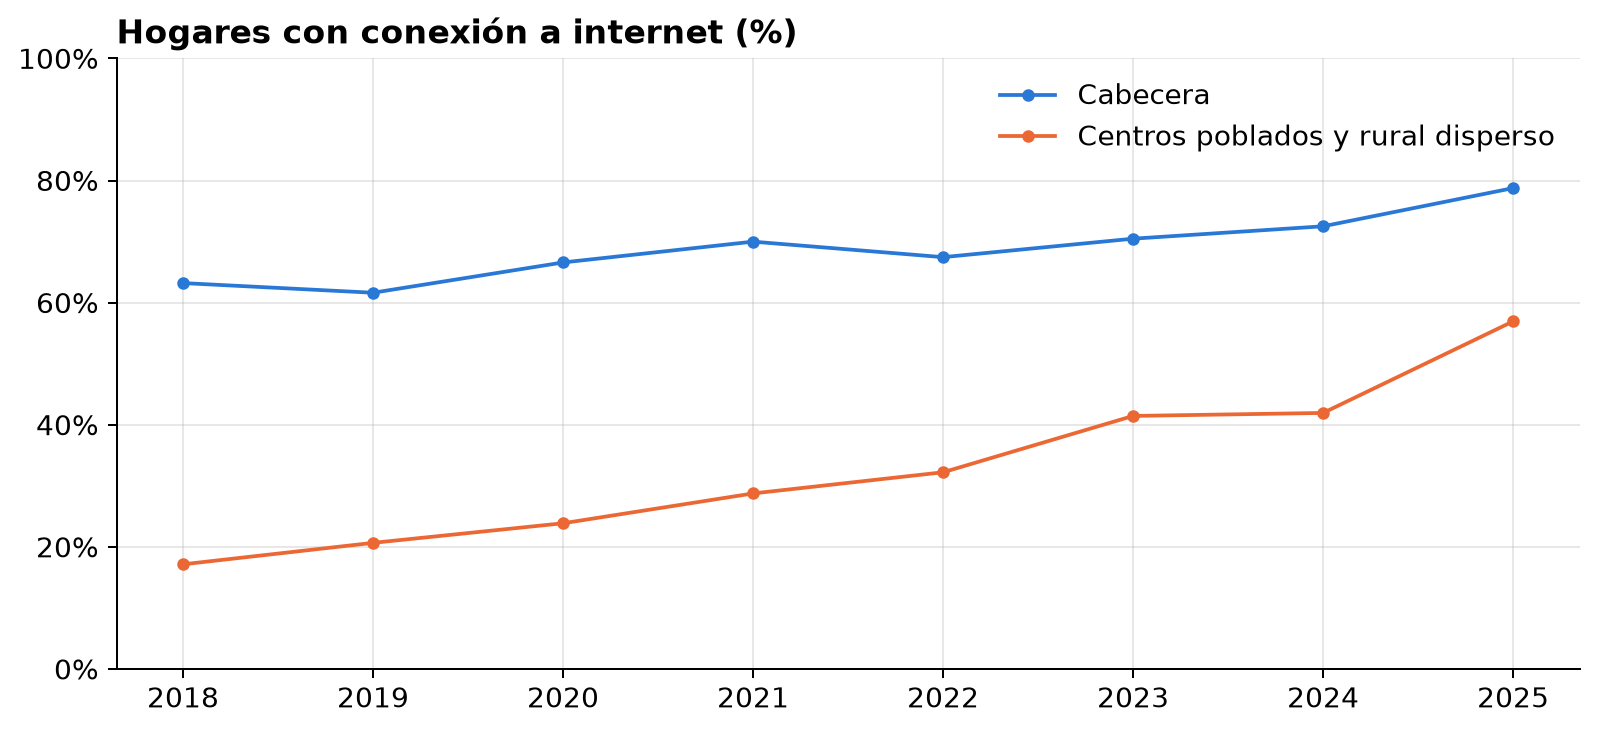

In [6]:
internet = dd.ecv.serie_indicadores(range(2018, 2026), por="area")
fig, ax = plt.subplots()
for nombre, d in internet.groupby("area", observed=True):
    ax.plot(d["anio"], d["pct_internet_hogar"], marker="o", markersize=4, label=nombre)
ax.set_title("Hogares con conexión a internet (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 100)
ax.legend()
fig.tight_layout()

```{seealso}
{doc}`../guia/ecv` explica los capítulos, las variables armonizadas, el IPM y lo que cambia con los años, y
{doc}`../guia/validacion` cómo se comparan las cifras con las del DANE.
```